# EDA 03 — Perhitungan Volatilitas Return Saham

Notebook ini digunakan untuk menghitung volatilitas return saham harian sebagai variabel target (Y) dalam penelitian tesis.

Analisis meliputi:
1. Import library dan konfigurasi path
2. Perhitungan rolling volatility (20 hari)
3. Statistik deskriptif volatilitas
4. Visualisasi time series volatilitas
5. Boxplot distribusi volatilitas antar emiten
6. Penyimpanan dataset hasil preprocessing

Output digunakan pada:
**BAB 4.3 Perhitungan Volatilitas Return (Variabel Y)**

In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARY & KONFIGURASI PATH
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# Konfigurasi visual
mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['figure.dpi'] = 200
plt.rcParams['figure.dpi'] = 200

# Path project (karena notebook berada di 02_preprocessing/EDA)
ROOT_DIR = Path('../../')

PROCESSED_DIR = ROOT_DIR / '03_dataset' / 'processed'
OUTPUT_DIR = ROOT_DIR / '06_dokumen_tesis'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Warna emiten konsisten
colors = {
    'ADRO': '#1f77b4',
    'ADMR': '#2ca02c',
    'ITMG': '#ff7f0e',
    'PTBA': '#d62728',
    'MEDC': '#9467bd',
    'AKRA': '#8c564b',
    'PGAS': '#e377c2'
}

print("Processed Folder:", PROCESSED_DIR.resolve())
print("Output Folder   :", OUTPUT_DIR.resolve())

Processed Folder: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed
Output Folder   : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis


## Perhitungan Rolling Volatility

Volatilitas return saham dihitung menggunakan metode **rolling standard deviation** dengan jendela pengamatan (*rolling window*) selama **10 hari perdagangan**.

Metode ini digunakan untuk mengukur tingkat fluktuasi return saham dalam horizon jangka pendek hingga menengah, sehingga perubahan volatilitas akibat dinamika pasar dan sentimen berita dapat diamati dengan lebih responsif.

Secara matematis, volatilitas pada waktu ke-\(t\) dihitung sebagai:

\[
\sigma_t = std(r_{t-9}, ..., r_t)
\]

dengan:

- \(\sigma_t\): volatilitas return pada periode ke-\(t\)
- \(r_t\): log return harian
- rolling window = 10 hari perdagangan

Pemilihan window 10 hari didasarkan pada pertimbangan bahwa periode tersebut merepresentasikan sekitar **dua minggu perdagangan bursa**, sehingga cukup sensitif untuk menangkap perubahan volatilitas jangka pendek tanpa menghasilkan noise yang berlebihan.

In [2]:
# ============================================================
# CELL 2 — LOAD LOG RETURN & HITUNG VOLATILITAS
# ============================================================

INPUT_FILE = PROCESSED_DIR / 'log_return.csv'

# Load dataset
df = pd.read_csv(INPUT_FILE, encoding='utf-8-sig')

# Rapikan kolom
df.columns = df.columns.str.strip()
df['Date'] = pd.to_datetime(df['Date'])

# Pastikan urut kronologis
df = df.sort_values(
    ['Kode_Emiten', 'Date']
).reset_index(drop=True)

# ------------------------------------------------------------
# PARAMETER ROLLING WINDOW
# Window 5 hari ≈ 1 minggu perdagangan bursa
# ------------------------------------------------------------
WINDOW = 5

# Hitung rolling volatility
df['Volatilitas'] = (
    df.groupby('Kode_Emiten')['Log_Return']
      .transform(
          lambda x: x.rolling(
              window=WINDOW,
              min_periods=WINDOW
          ).std()
      )
)

# Opsional: annualized volatility (jika nanti diperlukan)
# df['Volatilitas_Annualized'] = df['Volatilitas'] * np.sqrt(252)

print("="*60)
print(f"Rolling volatility berhasil dihitung (window={WINDOW} hari)")
print("="*60)

print("Shape dataset:", df.shape)
print("Jumlah missing akibat rolling:", df['Volatilitas'].isna().sum())

display(df.head(25))


print("="*80)
print("PERHITUNGAN ROLLING VOLATILITY")
print("="*80)

print(f"Rolling volatility berhasil dihitung menggunakan window = {WINDOW} hari.")
print()

print(
    "Pemilihan rolling window 5 hari didasarkan pada pertimbangan bahwa "
    "5 hari perdagangan merepresentasikan sekitar satu minggu aktivitas "
    "perdagangan di Bursa Efek Indonesia (BEI)."
)

print()

print(
    "Window 5 hari dipilih karena lebih sensitif dalam menangkap perubahan "
    "volatilitas jangka pendek akibat dinamika pasar dan sentimen berita "
    "harian yang menjadi fokus penelitian ini."
)

print()

print("Keunggulan penggunaan window 5 hari:")
print("- Lebih responsif terhadap shock pasar jangka pendek")
print("- Mampu menangkap dampak berita positif/negatif lebih cepat")
print("- Lebih sesuai untuk analisis sentimen berbasis berita harian")

print()
print("Shape dataset:", df.shape)
print("Jumlah missing akibat rolling:", df['Volatilitas'].isna().sum())

Rolling volatility berhasil dihitung (window=5 hari)
Shape dataset: (7455, 13)
Jumlah missing akibat rolling: 35


,Date,Open,High,Low,Close,Adj Close,Volume,Kode_Emiten,Nama_Perusahaan,Price_Model,Corporate_Action_Flag,Log_Return,Volatilitas
0,2022-01-03,135.0,135.0,135.0,135.0,125.224686,34289600,ADMR,Adaro Minerals Indonesia Tbk,125.224686,True,NaN,NaN
1,2022-01-04,182.0,182.0,182.0,182.0,168.821442,22170900,ADMR,Adaro Minerals Indonesia Tbk,168.821442,True,0.298732,NaN
2,2022-01-05,220.0,244.0,220.0,244.0,226.332031,43203600,ADMR,Adaro Minerals Indonesia Tbk,226.332031,True,0.293161,NaN
3,2022-01-06,304.0,304.0,304.0,304.0,281.987457,52097500,ADMR,Adaro Minerals Indonesia Tbk,281.987457,True,0.219860,NaN
4,2022-01-07,380.0,380.0,380.0,380.0,352.484314,19248600,ADMR,Adaro Minerals Indonesia Tbk,352.484314,True,0.223144,NaN
5,2022-01-10,474.0,474.0,474.0,474.0,439.677795,17843500,ADMR,Adaro Minerals Indonesia Tbk,439.677795,True,0.221036,0.040925
6,2022-01-11,494.0,590.0,494.0,590.0,547.278259,685732700,ADMR,Adaro Minerals Indonesia Tbk,547.278259,True,0.218915,0.032427
7,2022-01-12,635.0,735.0,620.0,735.0,681.778870,457330400,ADMR,Adaro Minerals Indonesia Tbk,681.778870,True,0.219748,0.001640
8,2022-01-13,735.0,735.0,735.0,735.0,681.778870,0,ADMR,Adaro Minerals Indonesia Tbk,681.778870,True,0.000000,0.098718
9,2022-01-14,780.0,890.0,700.0,790.0,732.796326,378668200,ADMR,Adaro Minerals Indonesia Tbk,732.796326,True,0.072162,0.103867


PERHITUNGAN ROLLING VOLATILITY
Rolling volatility berhasil dihitung menggunakan window = 5 hari.

Pemilihan rolling window 5 hari didasarkan pada pertimbangan bahwa 5 hari perdagangan merepresentasikan sekitar satu minggu aktivitas perdagangan di Bursa Efek Indonesia (BEI).

Window 5 hari dipilih karena lebih sensitif dalam menangkap perubahan volatilitas jangka pendek akibat dinamika pasar dan sentimen berita harian yang menjadi fokus penelitian ini.

Keunggulan penggunaan window 5 hari:
- Lebih responsif terhadap shock pasar jangka pendek
- Mampu menangkap dampak berita positif/negatif lebih cepat
- Lebih sesuai untuk analisis sentimen berbasis berita harian

Shape dataset: (7455, 13)
Jumlah missing akibat rolling: 35


## Statistik Deskriptif Volatilitas

Statistik yang dihitung:
- Mean
- Standard Deviation
- Minimum
- Maximum

Output digunakan sebagai **Tabel 4.7**

In [3]:
# ============================================================
# CELL 3 — STATISTIK DESKRIPTIF VOLATILITAS
# ============================================================

summary = []

for kode in sorted(df['Kode_Emiten'].unique()):
    data = df[df['Kode_Emiten'] == kode]['Volatilitas'].dropna()

    summary.append({
        'Kode_Emiten': kode,
        'Mean': data.mean(),
        'Std': data.std(),
        'Min': data.min(),
        'Max': data.max()
    })

vol_table = pd.DataFrame(summary).round(6)

display(vol_table)

vol_table.to_csv(
    OUTPUT_DIR / 'Tabel_4_7_statistik_volatilitas.csv',
    index=False,
    encoding='utf-8-sig'
)

,Kode_Emiten,Mean,Std,Min,Max
0,ADMR,0.032631,0.018144,0.001640,0.117258
1,ADRO,0.023282,0.015810,0.003906,0.175772
2,AKRA,0.022513,0.013051,0.002467,0.125719
3,ITMG,0.016839,0.010809,0.001777,0.065545
4,MEDC,0.028384,0.015202,0.003363,0.097330
5,PGAS,0.018006,0.009777,0.002634,0.069587
6,PTBA,0.017547,0.012294,0.001863,0.125571


## Grafik Time Series Volatilitas Rolling

Visualisasi ini digunakan untuk mengamati pola **volatility clustering**, yaitu kondisi ketika periode volatilitas tinggi cenderung diikuti oleh volatilitas tinggi.

Output digunakan sebagai **Gambar 4.7**

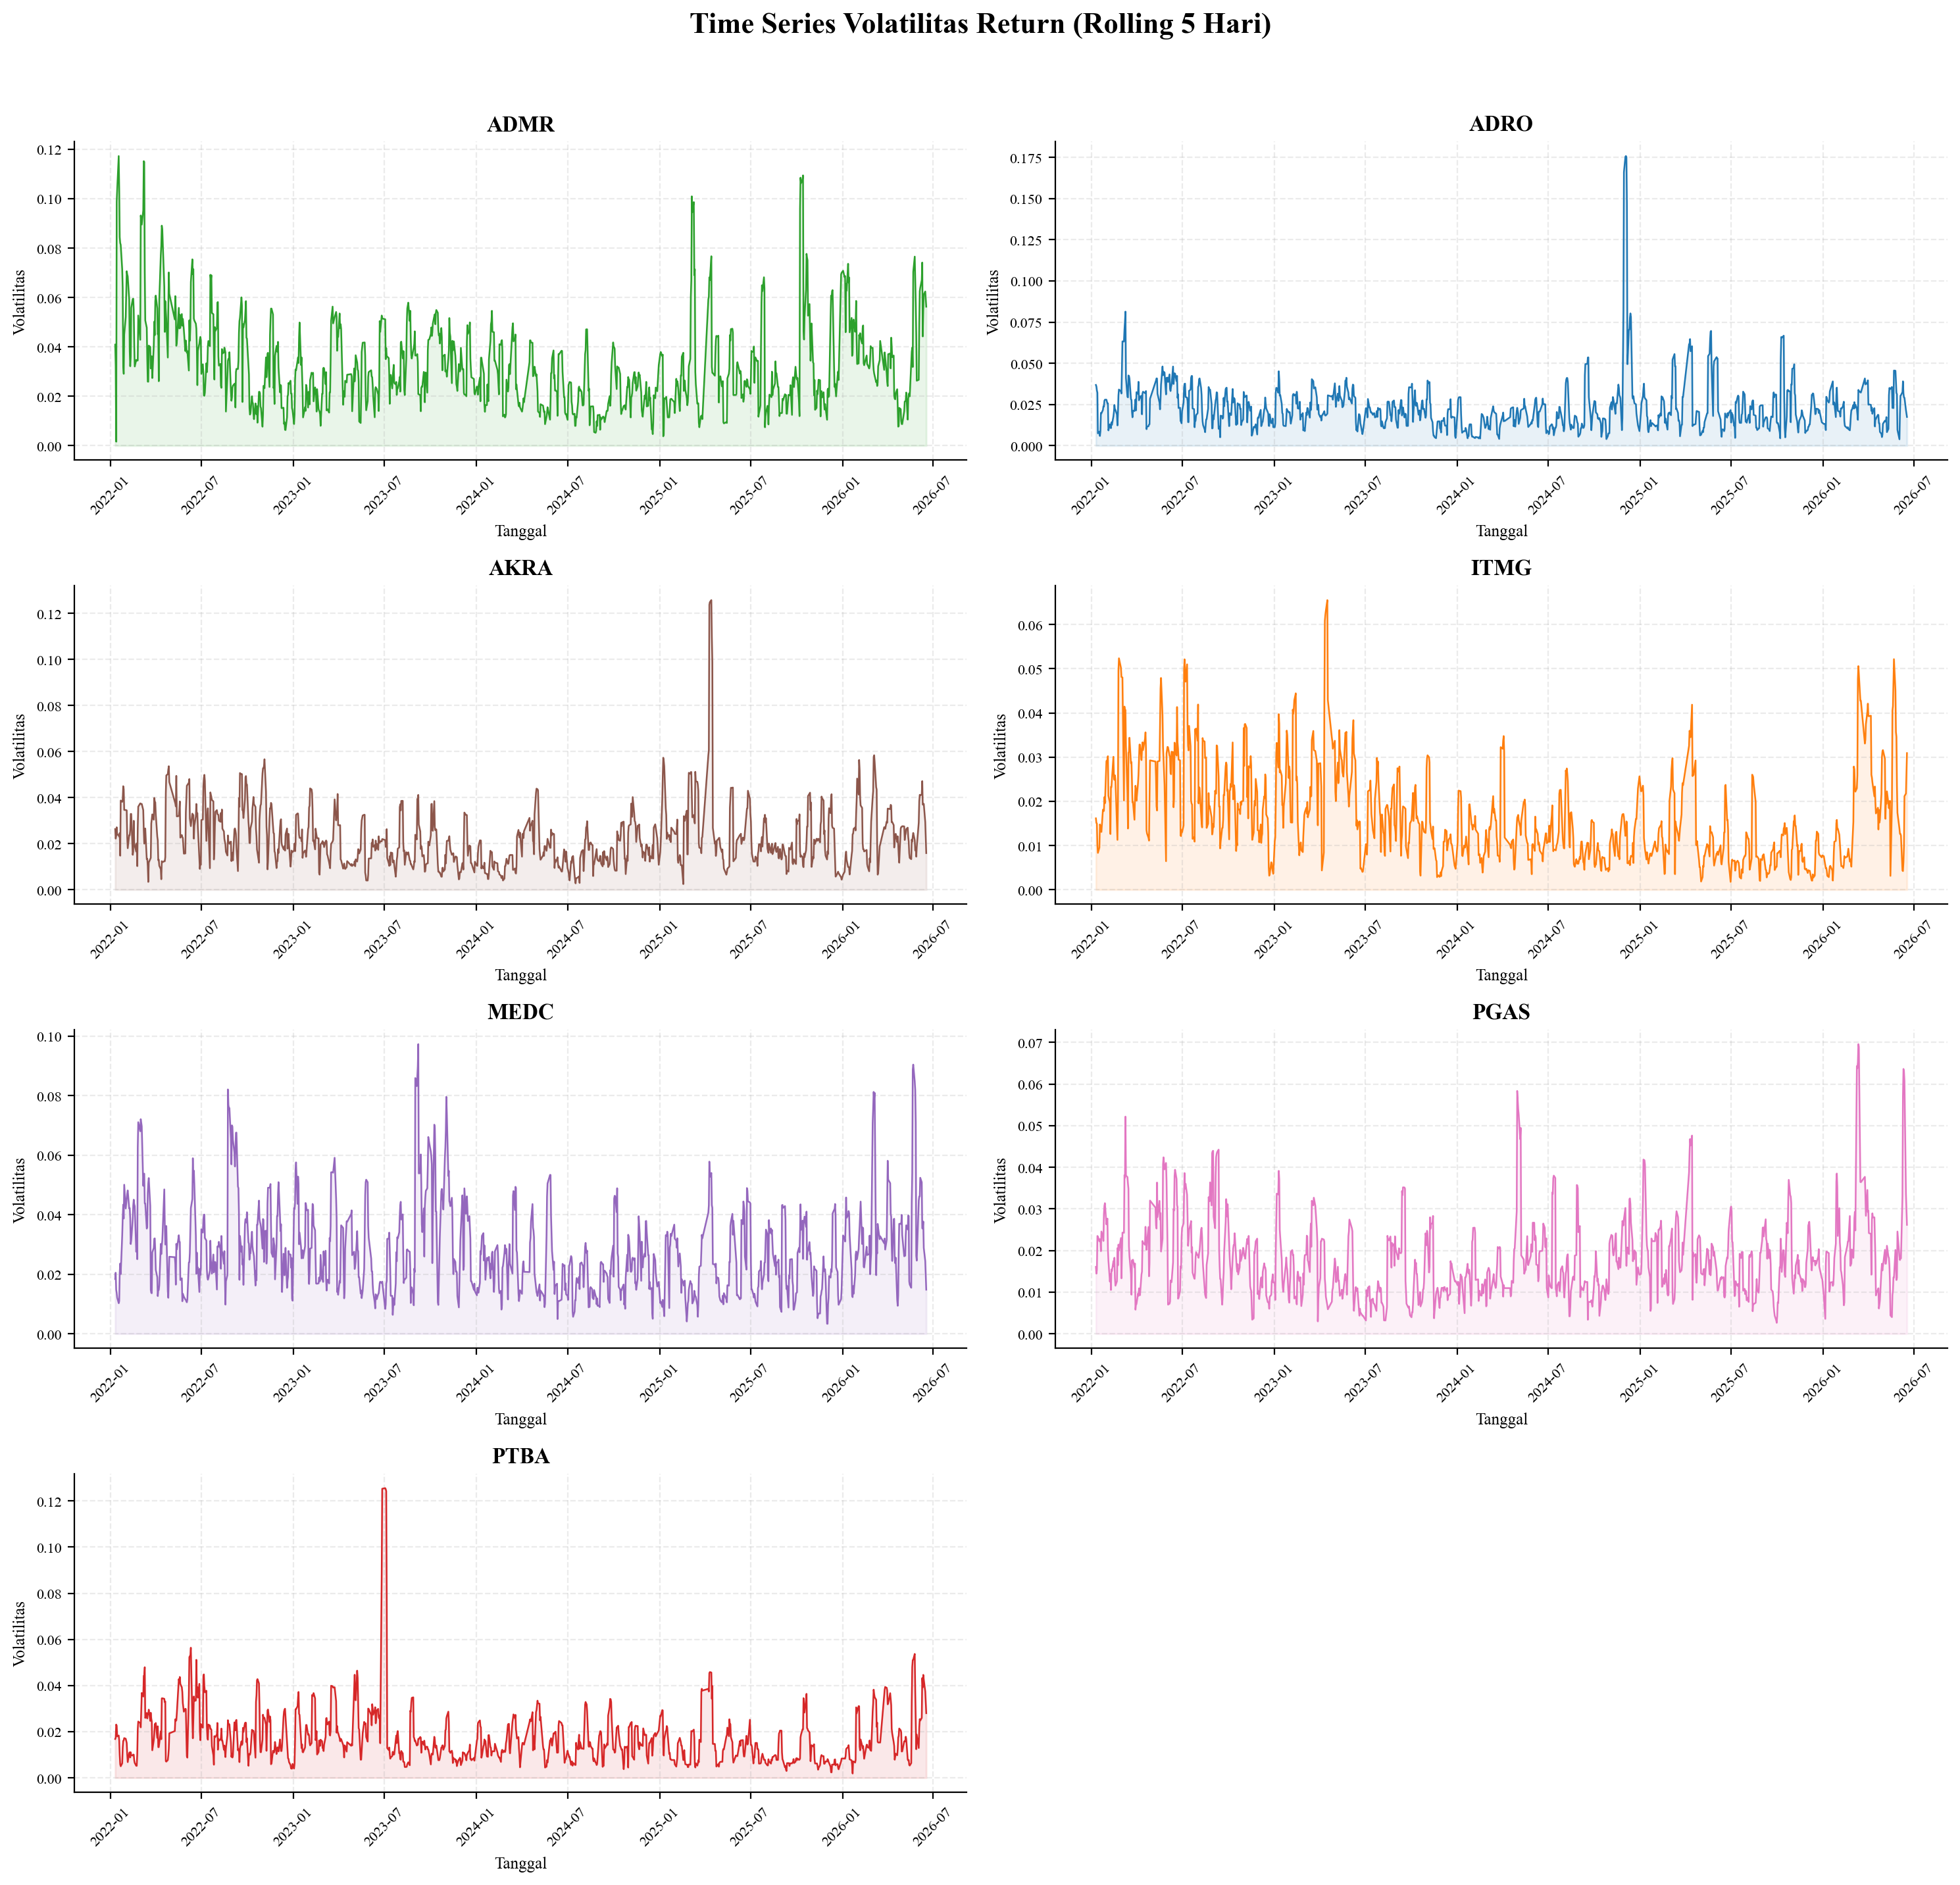

INTERPRETASI GRAFIK VOLATILITAS
Grafik menunjukkan pergerakan volatilitas return saham dengan rolling window 5 hari perdagangan.

Penggunaan rolling window 5 hari memungkinkan volatilitas merespons perubahan harga saham jangka pendek secara lebih sensitif.

Spike volatilitas yang muncul pada periode tertentu menunjukkan adanya fluktuasi pasar yang tinggi akibat shock eksternal maupun sentimen berita yang memengaruhi pergerakan saham sektor energi.


In [4]:
# ============================================================
# CELL 4 — TIME SERIES VOLATILITAS
# ============================================================

emitens = sorted(df['Kode_Emiten'].unique())

# Canvas subplot
fig, axes = plt.subplots(4, 2, figsize=(15, 14))
axes = axes.flatten()

for i, kode in enumerate(emitens):
    ax = axes[i]

    # Filter data per emiten
    sub = (
        df[df['Kode_Emiten'] == kode]
        .dropna(subset=['Volatilitas'])
        .copy()
    )

    # Plot garis volatilitas
    ax.plot(
        sub['Date'],
        sub['Volatilitas'],
        color=colors[kode],
        linewidth=0.9
    )

    # Area fill supaya lebih estetik
    ax.fill_between(
        sub['Date'],
        sub['Volatilitas'],
        color=colors[kode],
        alpha=0.10
    )

    # Judul subplot
    ax.set_title(
        f"{kode}",
        fontsize=12,
        fontweight='bold'
    )

    ax.set_xlabel("Tanggal", fontsize=9)
    ax.set_ylabel("Volatilitas", fontsize=9)

    # Grid halus
    ax.grid(
        alpha=0.25,
        linestyle='--'
    )

    # Rotasi tanggal
    ax.tick_params(
        axis='x',
        rotation=45,
        labelsize=8
    )

    ax.tick_params(
        axis='y',
        labelsize=8
    )

    # Hilangkan border atas-kanan
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hapus subplot kosong
for j in range(len(emitens), len(axes)):
    fig.delaxes(axes[j])

# Judul besar
plt.suptitle(
    f"Time Series Volatilitas Return (Rolling {WINDOW} Hari)",
    fontsize=16,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()

# Simpan gambar
plt.savefig(
    OUTPUT_DIR / "Gambar_4_7_time_series_volatilitas.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# INTERPRETASI SINGKAT
# ============================================================

print("="*80)
print("INTERPRETASI GRAFIK VOLATILITAS")
print("="*80)

print(
    f"Grafik menunjukkan pergerakan volatilitas return saham "
    f"dengan rolling window {WINDOW} hari perdagangan."
)

print()
print(
    "Penggunaan rolling window 5 hari memungkinkan volatilitas "
    "merespons perubahan harga saham jangka pendek secara lebih sensitif."
)

print()
print(
    "Spike volatilitas yang muncul pada periode tertentu menunjukkan "
    "adanya fluktuasi pasar yang tinggi akibat shock eksternal maupun "
    "sentimen berita yang memengaruhi pergerakan saham sektor energi."
)

## Boxplot Distribusi Volatilitas Antar Emiten

Boxplot digunakan untuk membandingkan:
- median volatilitas
- rentang interquartile
- outlier
- stabilitas relatif antar emiten

Output digunakan sebagai **Gambar 4.8**

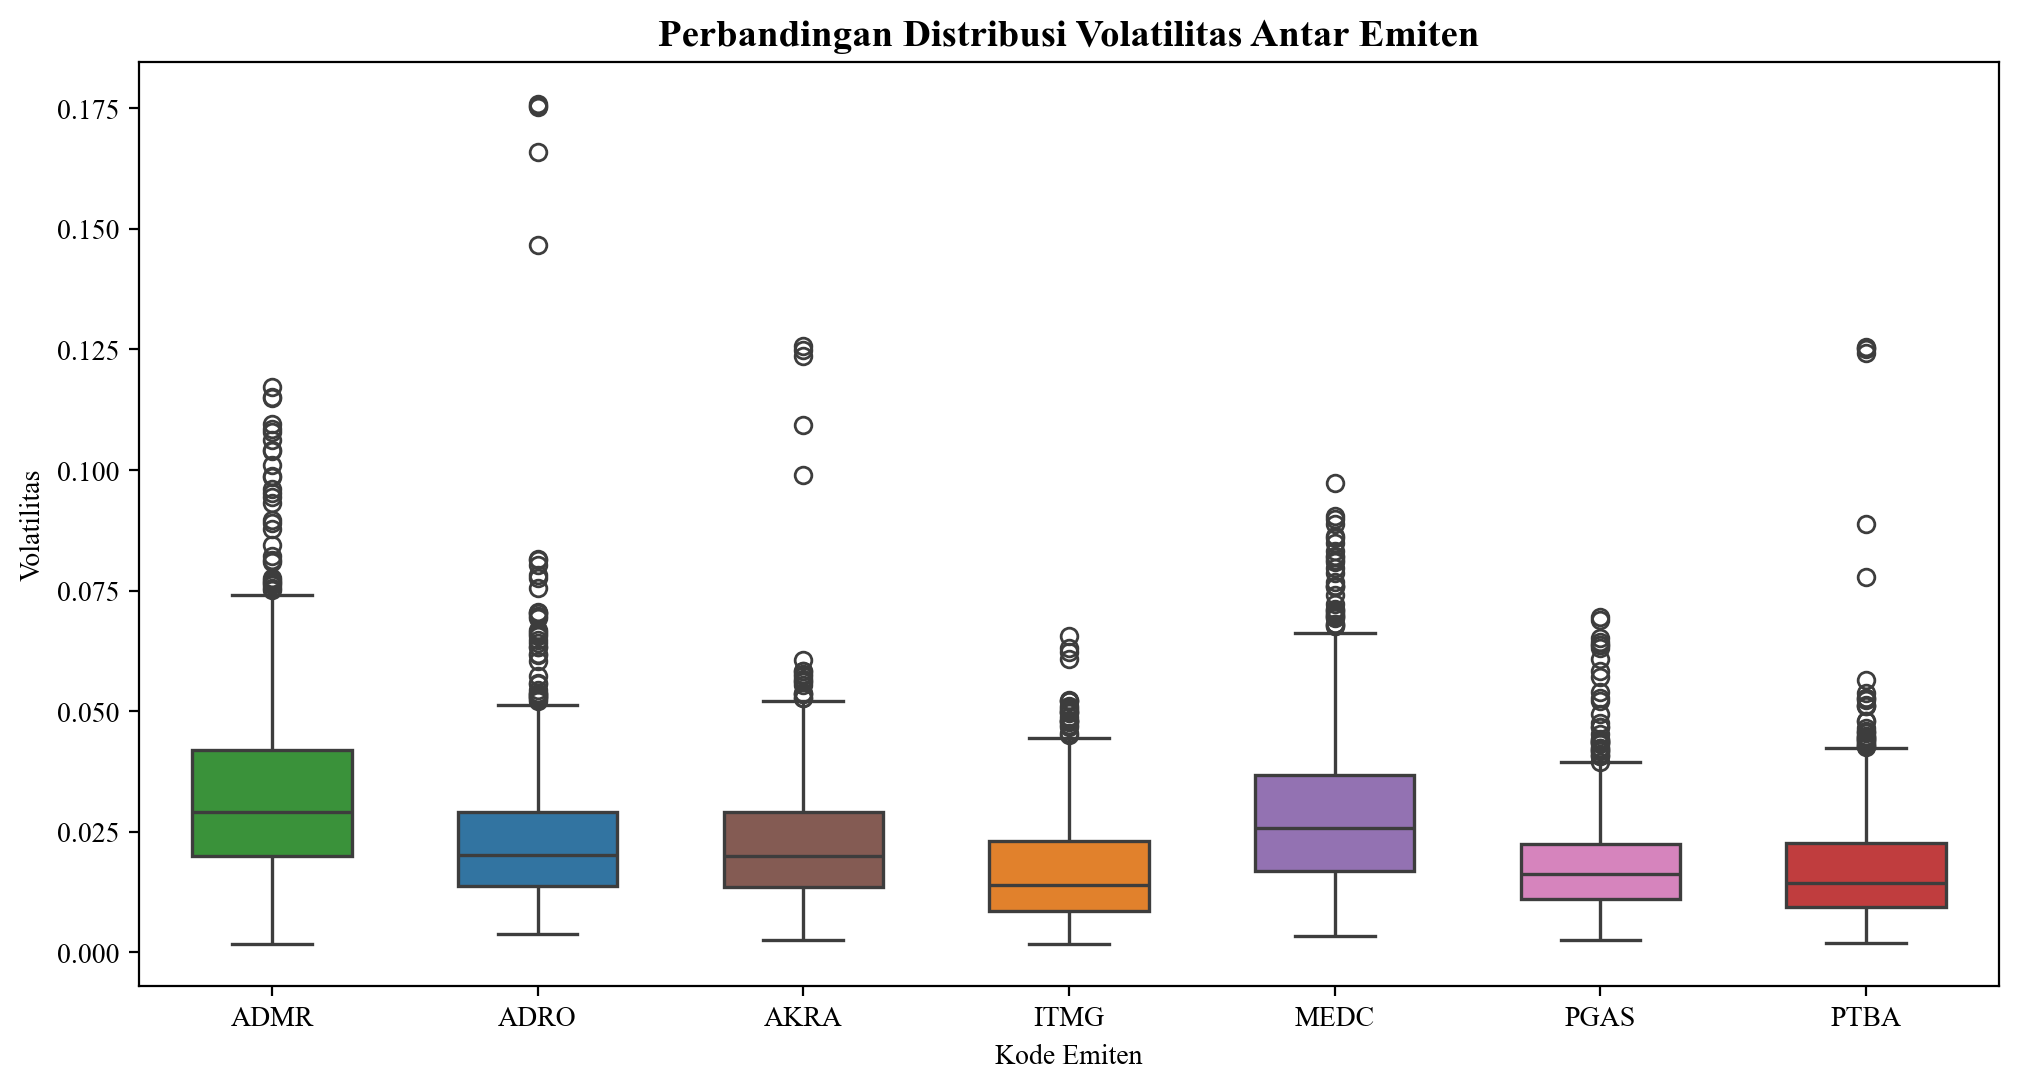

In [5]:
# ============================================================
# CELL 5 — BOXPLOT VOLATILITAS
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Kode_Emiten',
    y='Volatilitas',
    palette=colors,
    width=0.6,
    linewidth=1.2
)

plt.title(
    "Perbandingan Distribusi Volatilitas Antar Emiten",
    fontsize=14,
    fontweight='bold'
)

plt.xlabel("Kode Emiten")
plt.ylabel("Volatilitas")

plt.savefig(
    OUTPUT_DIR / "Gambar_4_8_boxplot_volatilitas.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()

## Simpan Dataset Volatilitas

Dataset volatilitas akan digunakan sebagai variabel target (Y) pada tahap feature engineering dan pemodelan.

In [6]:
# ============================================================
# CELL 6 — SAVE DATASET
# ============================================================

df.to_csv(
    PROCESSED_DIR / 'volatilitas.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Dataset berhasil disimpan:")
print(PROCESSED_DIR / 'volatilitas.csv')

Dataset berhasil disimpan:
..\..\03_dataset\processed\volatilitas.csv


## Ringkasan Output

Semua tabel, grafik, dan dataset volatilitas telah berhasil disimpan.

In [7]:
# ============================================================
# CELL 7 — SUMMARY OUTPUT
# ============================================================

files = [
    "Tabel_4_7_statistik_volatilitas.csv",
    "Gambar_4_7_time_series_volatilitas.png",
    "Gambar_4_8_boxplot_volatilitas.png"
]

print("Output Dokumen:")
for file in files:
    print("-", OUTPUT_DIR / file)

print("\nOutput Dataset:")
print("-", PROCESSED_DIR / "volatilitas.csv")

Output Dokumen:
- ..\..\06_dokumen_tesis\Tabel_4_7_statistik_volatilitas.csv
- ..\..\06_dokumen_tesis\Gambar_4_7_time_series_volatilitas.png
- ..\..\06_dokumen_tesis\Gambar_4_8_boxplot_volatilitas.png

Output Dataset:
- ..\..\03_dataset\processed\volatilitas.csv
